# Explore here

- Conectarse a la api del world bank v2
- Escoger 5 paises, en mi caso serán España, Méjico, Francia, Estados Unidos y Suecia

## Paso 1: preparar entorno y consulta api de ejemplo 

In [1]:
#primero de todo importar librerias
import requests
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sqlalchemy


## Paso 2: explorando la api 

In [2]:
# para este paso me voy a valer de la plantilla proporcionada en las instrucciones del proyecto
# primero miro endpoint de paises
url_paises = "https://api.worldbank.org/v2/country"
params = {
    "format": "json",
    "per_page": 5,
    "page": 1,
}

response = requests.get(url_paises, params=params, timeout=30)
response.raise_for_status()
payload = response.json()

# payload[0] -> metadatos de paginacion
# payload[1] -> datos de la pagina actual

print("Metadatos:", payload[0])
print("Primer elemento:", payload[1][0])

Metadatos: {'page': 1, 'pages': 60, 'per_page': '5', 'total': 296}
Primer elemento: {'id': 'ABW', 'iso2Code': 'AW', 'name': 'Aruba', 'region': {'id': 'LCN', 'iso2code': 'ZJ', 'value': 'Latin America & Caribbean '}, 'adminregion': {'id': '', 'iso2code': '', 'value': ''}, 'incomeLevel': {'id': 'HIC', 'iso2code': 'XD', 'value': 'High income'}, 'lendingType': {'id': 'LNX', 'iso2code': 'XX', 'value': 'Not classified'}, 'capitalCity': 'Oranjestad', 'longitude': '-70.0167', 'latitude': '12.5167'}


In [3]:
# ahora miro endpoint de indicadores 
url_indicadores = "https://api.worldbank.org/v2/indicator"
params = {
    "format": "json",
    "per_page": 5,
    "page": 1,
}

response = requests.get(url_indicadores, params=params, timeout=30)
response.raise_for_status()
payload = response.json()

print("Metadatos:", payload[0])
print("Primer indicador:", payload[1][0])

Metadatos: {'page': 1, 'pages': 5909, 'per_page': '5', 'total': 29544}
Primer indicador: {'id': '1.0.HCount.1.90usd', 'name': 'Poverty Headcount ($1.90 a day)', 'unit': '', 'source': {'id': '37', 'value': 'LAC Equity Lab'}, 'sourceNote': 'The poverty headcount index measures the proportion of the population with daily per capita income (in 2011 PPP) below the poverty line.', 'sourceOrganization': 'LAC Equity Lab tabulations of SEDLAC (CEDLAS and the World Bank).', 'topics': [{'id': '11', 'value': 'Poverty '}]}


## Paso 3: descargar los datos de la api

In [4]:
#necesito importar unas librerias adicionales para este paso 
import time

# lista de paises que quiero consultar
paises = ["ESP", "FRA", "MEX", "USA", "SWE"]

#lista de indicadores (recomendados en instrucciones)
indicadores = {
    "NY.GDP.PCAP.CD": "gdp_per_capita",
    "SP.DYN.LE00.IN": "life_expectancy",
    "EN.ATM.CO2E.PC": "co2_per_capita",
    "SP.POP.TOTL": "population",
}


BASE_URL = "https://api.worldbank.org/v2"
TIMEOUT = 60 

def fetch_indicator_data(country_code, indicator_id, start_year=2010, end_year=2024, max_retries=3): #funcion para obtener datos de un indicador específico para un país en un rango de años
    endpoint = f"{BASE_URL}/country/{country_code}/indicator/{indicator_id}" #URL para un indicador específico de un país
    page = 1
    all_rows = []

    while True:
        
        params = {
            "format": "json",
            "date": f"{start_year}:{end_year}",
            "per_page": 50,
            "page": page,
        }

        last_error = None
        payload = None

        for attempt in range(max_retries):
            try:
                response = requests.Session().get(endpoint, params=params, timeout=TIMEOUT)
                response.raise_for_status()
                payload = response.json()
                break
            except requests.exceptions.RequestException as exc:
                last_error = exc
                if attempt < max_retries - 1:
                    time.sleep(0.5 * (attempt + 1))

        if payload is None:
            print(f"No se pudo obtener datos para {country_code}/{indicator_id}: {last_error}")
            return all_rows

        if not isinstance(payload, list) or len(payload) < 2:
            break
        
        # extraer metadatos del payload
        metadata = payload[0] 
        rows = payload[1] or []
        all_rows.extend(rows)

       
        total_pages = int(metadata.get("pages", 1))
        if page >= total_pages:
            break
        page += 1

    return all_rows

In [5]:
# lista donde se almacenarán los registros obtenidos de la API
registros = []

# rellenamos la lista de registros con los datos obtenidos de la API para cada país e indicador
for pais in paises:
    for indicador in indicadores:
        rows = fetch_indicator_data(pais, indicador)
        for row in rows:
            registros.append({
                "pais": row.get("country", {}).get("value", pais),
                "indicador": indicador,
                "año": row.get("date"),
                "valor": row.get("value"),
            })

print(registros)

[{'pais': 'Spain', 'indicador': 'NY.GDP.PCAP.CD', 'año': '2024', 'valor': 35326.7683069278}, {'pais': 'Spain', 'indicador': 'NY.GDP.PCAP.CD', 'año': '2023', 'valor': 33493.2225409111}, {'pais': 'Spain', 'indicador': 'NY.GDP.PCAP.CD', 'año': '2022', 'valor': 30319.4987196616}, {'pais': 'Spain', 'indicador': 'NY.GDP.PCAP.CD', 'año': '2021', 'valor': 30799.4775937775}, {'pais': 'Spain', 'indicador': 'NY.GDP.PCAP.CD', 'año': '2020', 'valor': 27233.9426461608}, {'pais': 'Spain', 'indicador': 'NY.GDP.PCAP.CD', 'año': '2019', 'valor': 29786.5245689007}, {'pais': 'Spain', 'indicador': 'NY.GDP.PCAP.CD', 'año': '2018', 'valor': 30602.4212881113}, {'pais': 'Spain', 'indicador': 'NY.GDP.PCAP.CD', 'año': '2017', 'valor': 28381.3425596906}, {'pais': 'Spain', 'indicador': 'NY.GDP.PCAP.CD', 'año': '2016', 'valor': 26755.6061149398}, {'pais': 'Spain', 'indicador': 'NY.GDP.PCAP.CD', 'año': '2015', 'valor': 25982.4416197775}, {'pais': 'Spain', 'indicador': 'NY.GDP.PCAP.CD', 'año': '2014', 'valor': 29707.

## Paso 4: generar dataframes con la información obtenida

In [6]:
#creo el dataframe a partir de la lista de registros obtenidos
df = pd.DataFrame(registros)
#creo un diccionario tables que almacenará los dataframes de cada indicador, esto es para el paso final
tables = {}
#Eliminar filas con valores nulos
df = df.dropna(subset=["valor" , "año"])

# Convierto las columnas año y valor a los tipos de datos correctos (int y float respectivamente)
df["año"] = df["año"].astype(int)
df["valor"] = df["valor"].astype(float)

df.info() #miro que no hayan nulos con un info 

<class 'pandas.DataFrame'>
RangeIndex: 225 entries, 0 to 224
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   pais       225 non-null    str    
 1   indicador  225 non-null    str    
 2   año        225 non-null    int64  
 3   valor      225 non-null    float64
dtypes: float64(1), int64(1), str(2)
memory usage: 7.2 KB


## Paso 5: visualizar datos 
Según las instrucciones, se generarán 2 gráficos:
- Un line chartcon la evolucion de un indicador por pais, en mi caso la esperanza de vida
- Un scatter plot con la relación entre dos indicadores para un año reciente

Text(0, 0.5, 'Año')

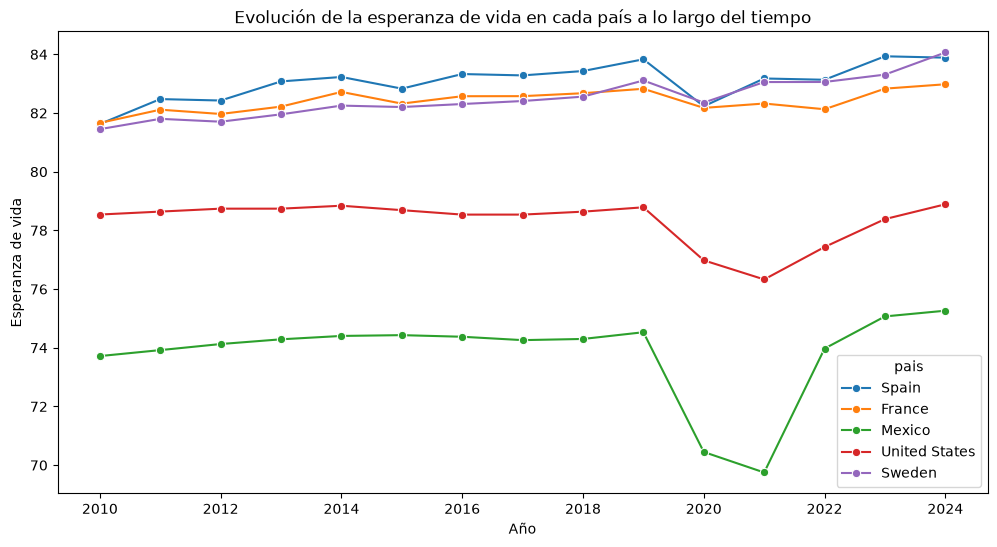

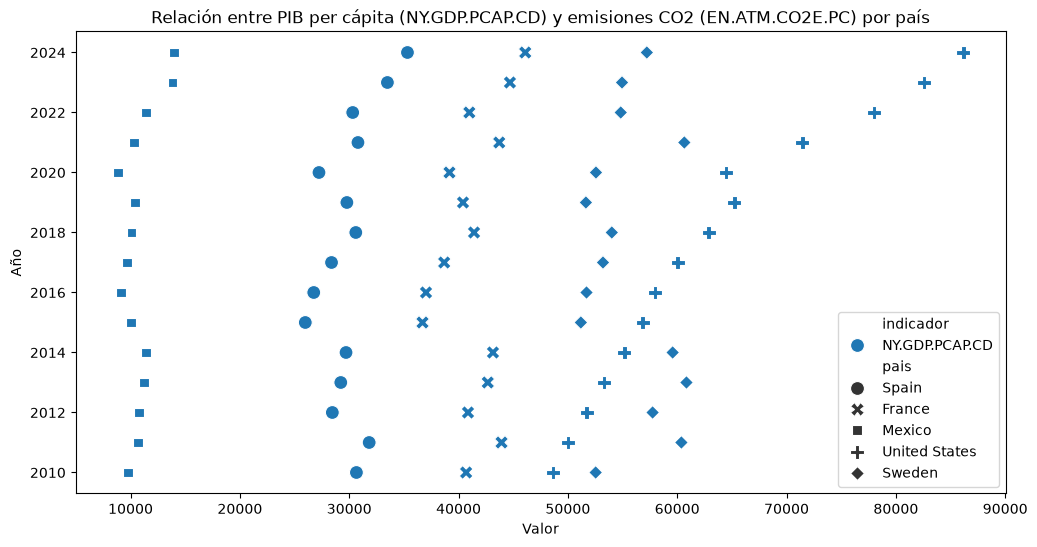

In [7]:
# grafico 1: evolución de la esperanza de vida en cada país a lo largo del tiempo
plt.figure(figsize=(12, 6))
sns.lineplot(data=df[df["indicador"] == "SP.DYN.LE00.IN"], x = "año", y = "valor", hue = "pais", marker = "o")
plt.title("Evolución de la esperanza de vida en cada país a lo largo del tiempo")
plt.xlabel("Año")
plt.ylabel("Esperanza de vida")

# grafico 2: relación entre PIB per cápita y emisiones CO2 (EN.ATM.CO2E.PC) 
plt.figure(figsize=(12, 6))
sns.scatterplot(
    data=df[df["indicador"].isin(["NY.GDP.PCAP.CD", "EN.ATM.CO2E.PC"])],
    x="valor",
    y="año",
    hue="indicador",
    style="pais",
    s=100,
)
plt.title("Relación entre PIB per cápita (NY.GDP.PCAP.CD) y emisiones CO2 (EN.ATM.CO2E.PC) por país")
plt.xlabel("Valor")
plt.ylabel("Año")   

- La esperana de vida tiene una tendencia creciente en todos los países, aunque llama la atención como en Méjico y Estados Unidos pega un bajón considerable en 2020 y 2021. Tal vez podría deberse al impacto del COVID en esos países, ya que se aprecia que también ocurre en los países europeos, aunque sin ser tan pronunciado.
- Estados Unidos tiene las mayores emisiones de CO2 y solo parecen ir en aumento, al contrario que en el resto de países donde se mantiene estable. No les debe de importar mucho el medio ambiente ahí.

## Paso 6: base de datos SQLite3

In [ ]:
import sqlite3
# he acabado usando sqlite3 al no conseguir que sqlalchemy funcionara correctamente 

# ruta de guardado de la base de datos SQLite
db_path = "world_bank_analysis.db"

# Guardar los datos en una base de datos SQLite
with sqlite3.connect(db_path) as connection:
    for indicator_id, indicator_df in df.groupby("indicador"):
        table_name = "indicator_" + indicator_id.lower().replace(".", "_")
        indicator_df[["pais", "año", "valor"]].to_sql(
            table_name, connection, if_exists="replace", index=False
        )

    # Validar la carga leyendo una muestra de la tabla de PIB per cápita
    sample = pd.read_sql_query(
        "SELECT * FROM indicator_ny_gdp_pcap_cd LIMIT 5", connection
    )

#comprobamos el guardado de la base de datos 
sample

,pais,año,valor
0,Spain,2024,35326.768307
1,Spain,2023,33493.222541
2,Spain,2022,30319.498720
3,Spain,2021,30799.477594
4,Spain,2020,27233.942646
